# CAP 5610 Midterm — Task 2
## Neural Network Regression on the King County Housing Dataset

The goal of this task is to predict house prices using a neural network
regression model.

The target variable will be log-transformed before training. Numerical
predictors will be standardized, and Logistic sigmoid and ReLU activation
functions will be compared using the same network architecture.

In [1]:
# Numerical and tabular data
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt

# Data preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Neural network regression
from sklearn.neural_network import MLPRegressor

# Model evaluation
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

## 1. Load the Training and Test Data

In [2]:
# Paths relative to the notebook directory.
train_path = "../data/king_county_train_.csv"
test_path = "../data/king_county_test_.csv"

# Load the supplied datasets.
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

Training shape: (16613, 19)
Test shape: (5000, 19)


In [3]:
print("Training columns:")
print(train_df.columns.tolist())

print("\nData types:")
print(train_df.dtypes)

print("\nFirst five rows:")
display(train_df.head())

print("\nMissing values in training data:")
missing_train = train_df.isna().sum()
print(missing_train[missing_train > 0])

print("\nMissing values in test data:")
missing_test = test_df.isna().sum()
print(missing_test[missing_test > 0])

Training columns:
['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']

Data types:
price              int64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

First five rows:


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,392000,3,1.50,1500,11975,1.0,0,0,4,7,1500,0,1970,0,98045,47.4658,-121.758,1510,13875
1,499950,3,2.50,3230,129578,1.0,0,0,4,8,2100,1130,1964,0,98014,47.6820,-121.913,2760,62059
2,510000,3,1.75,1480,7040,1.0,0,0,3,7,1480,0,1974,0,98033,47.6723,-122.169,2040,7810
3,648360,4,1.75,2260,7005,1.0,0,1,4,7,1130,1130,1947,0,98033,47.6895,-122.207,2330,9180
4,248000,4,2.25,2320,8760,1.0,0,0,4,8,1160,1160,1966,0,98032,47.3627,-122.285,1970,8690



Missing values in training data:
Series([], dtype: int64)

Missing values in test data:
Series([], dtype: int64)


## 3. Define the Target and Predictor Variables

`price` is the regression target.

Most predictors are numerical and will be standardized before being passed
to the neural network. `zipcode` is stored numerically in the dataset, but
it represents a geographic category rather than a continuous quantity, so
it is one-hot encoded instead of standardized.

Although the supplied data contain no missing values, imputation is kept
in the preprocessing pipeline so that missing values are handled
consistently if they occur.

In [4]:
# Separate predictors and target.
X = train_df.drop(columns=["price"])
y = train_df["price"]

# Keep the supplied test set separate for final evaluation.
X_test = test_df.drop(columns=["price"])
y_test = test_df["price"]

# Zip code is categorical even though it is stored as an integer.
categorical_features = ["zipcode"]

# All remaining predictors are treated as numerical.
numerical_features = [
    column for column in X.columns
    if column not in categorical_features
]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'lat', 'long', 'sqft_living15', 'sqft_lot15']

Categorical features:
['zipcode']


## 4. Log-Transform the Target

House prices are strongly right-skewed. The target is therefore transformed
using

$$
y_{\log} = \log(1+y).
$$

The neural network is trained to predict log-price. Predictions will later
be transformed back to dollars using `np.expm1()` before MSE and $R^2$ are
calculated.

In [5]:
# Apply the required log transformation to the target.
y_log = np.log1p(y)

print("Original price range:")
print(f"${y.min():,.0f} to ${y.max():,.0f}")

print("\nLog-transformed target range:")
print(f"{y_log.min():.4f} to {y_log.max():.4f}")

Original price range:
$75,000 to $7,700,000

Log-transformed target range:
11.2253 to 15.8567


## 5. Create Training and Validation Sets

A validation subset is created from the provided training data so that
network configurations can be compared without using the supplied test set.
The test set is reserved for the final evaluation.

In [6]:
# Split the provided training data into training and validation subsets.
X_train, X_val, y_train_log, y_val_log = train_test_split(
    X,
    y_log,
    test_size=0.20,
    random_state=42
)

print("Training subset:", X_train.shape)
print("Validation subset:", X_val.shape)

Training subset: (13290, 18)
Validation subset: (3323, 18)


## 6. Preprocessing Pipeline

Numerical predictors are median-imputed and standardized. Standardization
places the numerical variables on comparable scales, which is important
for stable neural-network optimization.

`zipcode` is imputed using its most frequent value and then one-hot encoded.

In [7]:
# Numerical preprocessing:
# 1. replace any missing values with the median
# 2. standardize each feature to approximately zero mean and unit variance
numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing for zipcode.
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Apply the appropriate preprocessing to each feature group.
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

## 7. Compare Sigmoid and ReLU Networks

Two neural networks are trained using the same architecture and training
parameters. The only difference between them is the hidden-layer activation
function.

Both networks use two hidden layers containing 64 and 32 neurons. The
output layer remains linear because this is a regression problem.

The models are compared using training time, number of iterations, and
validation-set prediction performance.

In [8]:
# Fit preprocessing only on the training subset.
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same fitted preprocessing to the validation subset.
X_val_processed = preprocessor.transform(X_val)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)

Processed training shape: (13290, 87)
Processed validation shape: (3323, 87)


In [9]:
# Import timing utility so training speed can be compared.
import time

# Shared network settings.
# Keeping these identical makes activation function the only experimental change.
network_parameters = {
    "hidden_layer_sizes": (64, 32),
    "solver": "adam",
    "learning_rate_init": 0.001,
    "max_iter": 500,
    "early_stopping": True,
    "validation_fraction": 0.10,
    "n_iter_no_change": 20,
    "random_state": 42
}

### 7.1 Logistic Sigmoid Network

In [10]:
# Create the sigmoid network.
sigmoid_model = MLPRegressor(
    activation="logistic",
    **network_parameters
)

# Measure training time.
start_time = time.perf_counter()

sigmoid_model.fit(
    X_train_processed,
    y_train_log
)

sigmoid_training_time = time.perf_counter() - start_time

print("Sigmoid iterations:", sigmoid_model.n_iter_)
print(f"Sigmoid training time: {sigmoid_training_time:.2f} seconds")
print(f"Sigmoid final training loss: {sigmoid_model.loss_:.6f}")

Sigmoid iterations: 350
Sigmoid training time: 55.91 seconds
Sigmoid final training loss: 0.011649


### 7.2 ReLU Network

In [11]:
# Create the ReLU network using exactly the same architecture
# and training settings as the sigmoid network.
relu_model = MLPRegressor(
    activation="relu",
    **network_parameters
)

# Measure training time.
start_time = time.perf_counter()

relu_model.fit(
    X_train_processed,
    y_train_log
)

relu_training_time = time.perf_counter() - start_time

print("ReLU iterations:", relu_model.n_iter_)
print(f"ReLU training time: {relu_training_time:.2f} seconds")
print(f"ReLU final training loss: {relu_model.loss_:.6f}")

ReLU iterations: 169
ReLU training time: 26.42 seconds
ReLU final training loss: 0.013135


### 7.3 Validation Performance

In [12]:
# Generate validation predictions on the log-price scale.
sigmoid_val_log = sigmoid_model.predict(X_val_processed)
relu_val_log = relu_model.predict(X_val_processed)

# Convert predictions back to the original dollar scale.
sigmoid_val_price = np.expm1(sigmoid_val_log)
relu_val_price = np.expm1(relu_val_log)

# Convert the validation targets back to dollars as well.
y_val_price = np.expm1(y_val_log)

# Calculate validation metrics on the original monetary scale.
sigmoid_val_mse = mean_squared_error(
    y_val_price,
    sigmoid_val_price
)
sigmoid_val_r2 = r2_score(
    y_val_price,
    sigmoid_val_price
)

relu_val_mse = mean_squared_error(
    y_val_price,
    relu_val_price
)
relu_val_r2 = r2_score(
    y_val_price,
    relu_val_price
)

activation_comparison = pd.DataFrame({
    "Activation": ["Sigmoid", "ReLU"],
    "Iterations": [
        sigmoid_model.n_iter_,
        relu_model.n_iter_
    ],
    "Training Time (s)": [
        sigmoid_training_time,
        relu_training_time
    ],
    "Validation MSE": [
        sigmoid_val_mse,
        relu_val_mse
    ],
    "Validation R2": [
        sigmoid_val_r2,
        relu_val_r2
    ]
})

activation_comparison

,Activation,Iterations,Training Time (s),Validation MSE,Validation R2
0,Sigmoid,350,55.913585,1.779157e+10,0.879766
1,ReLU,169,26.420860,5.297816e+14,-3579.230619


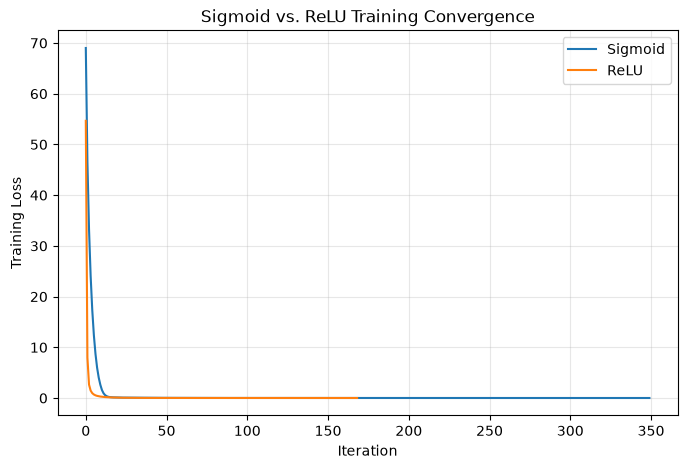

In [13]:
# Plot training loss across iterations for both activation functions.
plt.figure(figsize=(8, 5))

plt.plot(
    sigmoid_model.loss_curve_,
    label="Sigmoid"
)

plt.plot(
    relu_model.loss_curve_,
    label="ReLU"
)

plt.xlabel("Iteration")
plt.ylabel("Training Loss")
plt.title("Sigmoid vs. ReLU Training Convergence")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### 7.4 Inspect Validation Prediction Ranges

Because the ReLU model produces a very large error after predictions are
converted back to dollars, its predictions are inspected on both the
log-price and original price scales. This helps determine whether a small
number of extreme predictions are driving the validation MSE.

In [14]:
# Compare errors directly on the log-price scale.
sigmoid_log_mse = mean_squared_error(
    y_val_log,
    sigmoid_val_log
)

relu_log_mse = mean_squared_error(
    y_val_log,
    relu_val_log
)

sigmoid_log_r2 = r2_score(
    y_val_log,
    sigmoid_val_log
)

relu_log_r2 = r2_score(
    y_val_log,
    relu_val_log
)

print("Validation log-scale metrics")
print(
    f"Sigmoid: MSE = {sigmoid_log_mse:.6f}, "
    f"R2 = {sigmoid_log_r2:.4f}"
)
print(
    f"ReLU:    MSE = {relu_log_mse:.6f}, "
    f"R2 = {relu_log_r2:.4f}"
)

print("\nObserved validation log-price range:")
print(
    f"{y_val_log.min():.4f} to "
    f"{y_val_log.max():.4f}"
)

print("\nPredicted log-price ranges:")
print(
    f"Sigmoid: {sigmoid_val_log.min():.4f} to "
    f"{sigmoid_val_log.max():.4f}"
)
print(
    f"ReLU:    {relu_val_log.min():.4f} to "
    f"{relu_val_log.max():.4f}"
)

print("\nPredicted dollar ranges:")
print(
    f"Sigmoid: ${sigmoid_val_price.min():,.0f} to "
    f"${sigmoid_val_price.max():,.0f}"
)
print(
    f"ReLU:    ${relu_val_price.min():,.0f} to "
    f"${relu_val_price.max():,.0f}"
)

Validation log-scale metrics
Sigmoid: MSE = 0.028885, R2 = 0.8972
ReLU:    MSE = 0.055486, R2 = 0.8026

Observed validation log-price range:
11.2898 to 15.7449

Predicted log-price ranges:
Sigmoid: 11.7801 to 15.3114
ReLU:    11.7545 to 21.0064

Predicted dollar ranges:
Sigmoid: $130,628 to $4,463,316
ReLU:    $127,324 to $1,327,327,364


In [15]:
# Inspect the observations with the largest absolute ReLU errors.
relu_errors = np.abs(
    relu_val_price - y_val_price.to_numpy()
)

worst_indices = np.argsort(relu_errors)[-10:][::-1]

relu_error_table = pd.DataFrame({
    "Actual Price": y_val_price.iloc[worst_indices].to_numpy(),
    "ReLU Prediction": relu_val_price[worst_indices],
    "Sigmoid Prediction": sigmoid_val_price[worst_indices],
    "Absolute ReLU Error": relu_errors[worst_indices]
})

relu_error_table

,Actual Price,ReLU Prediction,Sigmoid Prediction,Absolute ReLU Error
0,640000.0,1.327327e+09,3.266954e+05,1.326687e+09
1,937500.0,1.515490e+07,1.412628e+06,1.421740e+07
2,3200000.0,1.116329e+07,3.782619e+06,7.963286e+06
3,6885000.0,1.232286e+07,4.463316e+06,5.437862e+06
4,1680000.0,4.028052e+06,3.037029e+06,2.348052e+06
5,4208000.0,2.186744e+06,2.170502e+06,2.021256e+06
6,2535000.0,4.397095e+06,2.411444e+06,1.862095e+06
7,490000.0,2.298335e+06,2.059947e+06,1.808335e+06
8,2458000.0,3.957989e+06,3.231957e+06,1.499989e+06
9,1295000.0,2.727546e+06,2.287934e+06,1.432546e+06


### 7.5 Activation Function Comparison

ReLU converged substantially faster than sigmoid, requiring 169 iterations
and approximately 26.4 seconds, compared with 350 iterations and
approximately 55.9 seconds for sigmoid.

However, sigmoid produced substantially better validation predictions.
On the log-price scale, sigmoid achieved an $R^2$ of 0.8972 compared with
0.8026 for ReLU.

The difference became much larger after predictions were transformed back
to dollars. The ReLU model produced an extreme log-price prediction of
21.0064, which corresponds to approximately 1.33 billion after applying
the inverse log transformation. Because Mean Squared Error heavily
penalizes large errors, this extreme prediction caused the ReLU
dollar-scale MSE to increase dramatically and produced a negative
dollar-scale $R^2$.

Sigmoid produced a much more reasonable prediction range and achieved a
validation $R^2$ of 0.8798 on the original price scale. Therefore, sigmoid
was selected as the final activation function. ReLU trained faster, but
sigmoid provided substantially more reliable predictions for this dataset.

## 8. Final Sigmoid Model

Based on validation performance, logistic sigmoid is selected as the
activation function for the final model.

The preprocessing pipeline is refitted using the complete provided training
set. The final network uses the same architecture and training parameters
used during the activation-function comparison.

In [16]:
# Refit preprocessing using the complete supplied training dataset.
X_full_processed = preprocessor.fit_transform(X)

# Transform the untouched supplied test set using the same fitted preprocessing.
X_test_processed = preprocessor.transform(X_test)

print("Final training shape:", X_full_processed.shape)
print("Final test shape:", X_test_processed.shape)

Final training shape: (16613, 87)
Final test shape: (5000, 87)


In [17]:
# Train the final model using the selected sigmoid activation.
final_model = MLPRegressor(
    activation="logistic",
    **network_parameters
)

start_time = time.perf_counter()

final_model.fit(
    X_full_processed,
    y_log
)

final_training_time = time.perf_counter() - start_time

print("Final model iterations:", final_model.n_iter_)
print(f"Final model training time: {final_training_time:.2f} seconds")
print(f"Final model training loss: {final_model.loss_:.6f}")

Final model iterations: 285
Final model training time: 57.68 seconds
Final model training loss: 0.012263


## 9. Final Test-Set Evaluation

Predictions are first generated on the log-price scale and then converted
back to the original dollar scale using `np.expm1()`.

Mean Squared Error and $R^2$ are calculated using the original house
prices, as required for the final evaluation.

In [18]:
# Predict log-prices for the untouched test set.
test_predictions_log = final_model.predict(X_test_processed)

# Convert predictions back to dollars.
test_predictions = np.expm1(test_predictions_log)

# Calculate final test metrics on the original monetary scale.
test_mse = mean_squared_error(
    y_test,
    test_predictions
)

test_r2 = r2_score(
    y_test,
    test_predictions
)

print(f"Final Test MSE: {test_mse:,.2f}")
print(f"Final Test R2: {test_r2:.4f}")

Final Test MSE: 14,209,013,074.81
Final Test R2: 0.9019


## 10. Naive Mean Baseline

A naive regression baseline predicts the same value for every test
observation: the mean house price from the training data. This provides a
reference for determining whether the neural network has learned useful
predictive relationships.

In [19]:
# Use the mean training price as the naive prediction.
training_mean_price = y.mean()

baseline_predictions = np.full(
    shape=len(y_test),
    fill_value=training_mean_price
)

baseline_mse = mean_squared_error(
    y_test,
    baseline_predictions
)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)

print(f"Training mean price: ${training_mean_price:,.2f}")
print(f"Baseline Test MSE: {baseline_mse:,.2f}")
print(f"Baseline Test R2: {baseline_r2:.4f}")

Training mean price: $538,144.28
Baseline Test MSE: 144,913,135,355.29
Baseline Test R2: -0.0005


In [20]:
final_comparison = pd.DataFrame({
    "Model": [
        "Naive Mean Baseline",
        "Final Sigmoid Neural Network"
    ],
    "Test MSE": [
        baseline_mse,
        test_mse
    ],
    "Test R2": [
        baseline_r2,
        test_r2
    ]
})

final_comparison

,Model,Test MSE,Test R2
0,Naive Mean Baseline,1.449131e+11,-0.000487
1,Final Sigmoid Neural Network,1.420901e+10,0.901900
